# DATA PREPARATION

In [ ]:
from __future__ import annotations

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1]
sys.path.append(str(ROOT / "DatabaseScripts"))

# This is a Class we made for an easier access of the data from the .parquet files
from DataFilter import MetroDataQuery

PARQUET_PATH = ROOT / "metro_passengers.parquet"
STATION_ID = 8603328  # Copenhagen Airport
SYSTEM = "m1m2"

In [166]:
# Load Airport station Data
query = (
    MetroDataQuery(PARQUET_PATH)
    .filter_station_id(STATION_ID)
    .filter_system(SYSTEM)
)

df_raw = query.to_pandas(sort_by_time=True)

df_raw.head()

,timestamp,stationId,system,station,ins,outs,passengerNo
0,2024-04-01 00:00:00+00:00,8603328,m1m2,Københavns Lufthavn,33.000000000,5.000000000,19.000000000
1,2024-04-01 00:01:00+00:00,8603328,m1m2,Københavns Lufthavn,29.000000000,2.000000000,15.500000000
2,2024-04-01 00:02:00+00:00,8603328,m1m2,Københavns Lufthavn,35.000000000,5.000000000,20.000000000
3,2024-04-01 00:03:00+00:00,8603328,m1m2,Københavns Lufthavn,22.000000000,4.000000000,13.000000000
4,2024-04-01 00:04:00+00:00,8603328,m1m2,Københavns Lufthavn,20.000000000,13.000000000,16.500000000


In [168]:
df_raw.shape, df_raw.columns

((1051200, 7),
 Index(['timestamp', 'stationId', 'system', 'station', 'ins', 'outs',
        'passengerNo'],
       dtype='str'))

In [169]:
# Basic cleaning 
df = df_raw.copy()

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

for col in ["ins", "outs"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    df[col] = df[col].clip(lower=0)

df = df.sort_values("timestamp")

df[["timestamp", "ins", "outs"]].head()

,timestamp,ins,outs
0,2024-04-01 00:00:00+00:00,33.0,5.0
1,2024-04-01 00:01:00+00:00,29.0,2.0
2,2024-04-01 00:02:00+00:00,35.0,5.0
3,2024-04-01 00:03:00+00:00,22.0,4.0
4,2024-04-01 00:04:00+00:00,20.0,13.0


In [170]:
# Total demand and direction variables
df["total"] = df["ins"] + df["outs"]

# outs_share = how much of total flow is airport-bound
df["outs_share"] = np.where(
    df["total"] > 0,
    df["outs"] / df["total"],
    np.nan
)

df[["timestamp", "ins", "outs", "total", "outs_share"]].head()

,timestamp,ins,outs,total,outs_share
0,2024-04-01 00:00:00+00:00,33.0,5.0,38.0,0.131579
1,2024-04-01 00:01:00+00:00,29.0,2.0,31.0,0.064516
2,2024-04-01 00:02:00+00:00,35.0,5.0,40.0,0.125000
3,2024-04-01 00:03:00+00:00,22.0,4.0,26.0,0.153846
4,2024-04-01 00:04:00+00:00,20.0,13.0,33.0,0.393939


In [171]:
zero_rows = ((df["ins"] == 0) & (df["outs"] == 0)).sum()
total_rows = len(df)

print(f"Zero-flow rows: {zero_rows:,} / {total_rows:,} ({100 * zero_rows / total_rows:.2f}%)")

Zero-flow rows: 137,660 / 1,051,200 (13.10%)


In [172]:
# Removing zero-total rows:
df = df[df["total"] > 0].copy()

In [173]:
# Aggregate to 15-minute intervals
df_15 = (
    df.set_index("timestamp")
      .resample("15min")[["ins", "outs"]]
      .sum()
      .reset_index()
)

df_15["total"] = df_15["ins"] + df_15["outs"]

# remove empty 15-min bins
df_15 = df_15[df_15["total"] > 0].copy()

df_15["outs_share"] = df_15["outs"] / df_15["total"]

df_15.head()

,timestamp,ins,outs,total,outs_share
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481


In [174]:
df_15["hour"] = df_15["timestamp"].dt.hour
df_15["minute"] = df_15["timestamp"].dt.minute
df_15["slot"] = df_15["hour"] * 4 + df_15["minute"] // 15  # 0,...,95

df_15["weekday"] = df_15["timestamp"].dt.dayofweek  # Monday=0
df_15["month"] = df_15["timestamp"].dt.month - 1     # 0,...,11 
df_15["is_weekend"] = (df_15["weekday"] >= 5).astype(int)

df_15.head()

,timestamp,ins,outs,total,outs_share,hour,minute,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,0,15,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,0,30,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,0,45,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,1,0,4,0,3,0


In [175]:
# Sanity checks
print(df_15.shape)
print(df_15["timestamp"].min(), "→", df_15["timestamp"].max())

print(df_15[["ins", "outs", "total", "outs_share"]].describe())

print("Slots:", df_15["slot"].min(), df_15["slot"].max())
print("Weekdays:", sorted(df_15["weekday"].unique()))
print("Months:", sorted(df_15["month"].unique()))

(69111, 11)
2024-04-01 00:00:00+00:00 → 2026-03-31 23:45:00+00:00
                ins          outs         total    outs_share
count  69111.000000  69111.000000  69111.000000  69111.000000
mean     133.257267    153.547785    286.805053      0.545344
std       90.591999     98.958744    166.297945      0.203307
min        0.000000      0.000000      1.000000      0.000000
25%       47.000000     66.000000    159.000000      0.404720
50%      139.000000    155.000000    295.000000      0.531707
75%      198.000000    230.000000    410.000000      0.652174
max      903.000000    695.000000   1392.000000      1.000000
Slots: 0 95
Weekdays: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
Months: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11)]


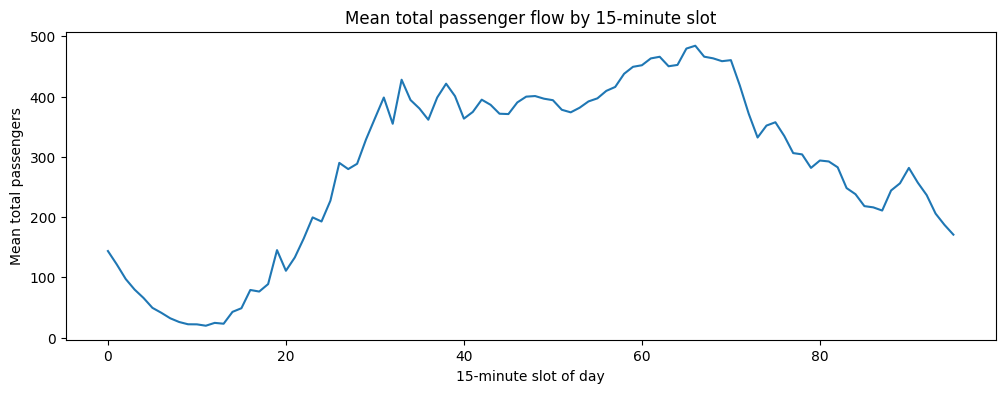

In [176]:
slot_profile = df_15.groupby("slot")["total"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(slot_profile.index, slot_profile.values)
ax.set_title("Mean total passenger flow by 15-minute slot")
ax.set_xlabel("15-minute slot of day")
ax.set_ylabel("Mean total passengers")
plt.show()

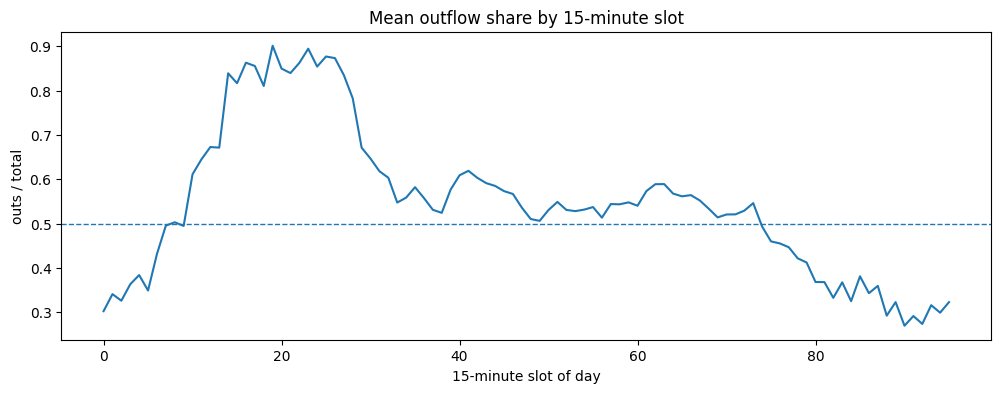

In [177]:
slot_direction = df_15.groupby("slot")["outs_share"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(slot_direction.index, slot_direction.values)
ax.axhline(0.5, linestyle="--", linewidth=1)
ax.set_title("Mean outflow share by 15-minute slot")
ax.set_xlabel("15-minute slot of day")
ax.set_ylabel("outs / total")
plt.show()

In [178]:
# Saving the modelling dataframe
model_df = df_15[[
    "timestamp",
    "ins",
    "outs",
    "total",
    "outs_share",
    "slot",
    "weekday",
    "month",
    "is_weekend",
]].copy()

model_df.to_parquet("airport_15min_model_data.parquet", index=False)

model_df.head()

,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0


# BASELINES

In [ ]:
# loading data
model_df = pd.read_parquet("airport_15min_model_data.parquet")

model_df["timestamp"] = pd.to_datetime(model_df["timestamp"], utc=True)
model_df = model_df.sort_values("timestamp").reset_index(drop=True)

model_df.head()

In [179]:
# Train/test split
split_date = model_df["timestamp"].quantile(0.8)

train_df = model_df[model_df["timestamp"] <= split_date].copy()
test_df  = model_df[model_df["timestamp"] > split_date].copy()

print(train_df["timestamp"].min(), "→", train_df["timestamp"].max(), len(train_df))
print(test_df["timestamp"].min(), "→", test_df["timestamp"].max(), len(test_df))

2024-04-01 00:00:00+00:00 → 2025-11-05 22:30:00+00:00 55289
2025-11-05 22:45:00+00:00 → 2026-03-31 23:45:00+00:00 13822


In [180]:
# Baseline A: global average
global_total_mean = train_df["total"].mean()
global_outs_share = train_df["outs_share"].mean()

test_df["pred_total_global"] = global_total_mean
test_df["pred_outs_share_global"] = global_outs_share

test_df["pred_outs_global"] = test_df["pred_total_global"] * test_df["pred_outs_share_global"]
test_df["pred_ins_global"] = test_df["pred_total_global"] - test_df["pred_outs_global"]

In [ ]:
# Baseline B: slot of day average
slot_stats = (
    train_df
    .groupby("slot")
    .agg(
        pred_total_slot=("total", "mean"),
        pred_outs_share_slot=("outs_share", "mean")
    )
    .reset_index()
)

test_df = test_df.merge(slot_stats, on="slot", how="left")

test_df["pred_total_slot"] = test_df["pred_total_slot"].fillna(global_total_mean)
test_df["pred_outs_share_slot"] = test_df["pred_outs_share_slot"].fillna(global_outs_share)

test_df["pred_outs_slot"] = test_df["pred_total_slot"] * test_df["pred_outs_share_slot"]
test_df["pred_ins_slot"] = test_df["pred_total_slot"] - test_df["pred_outs_slot"]

In [182]:
# Baseline C: slot + weekday average
slot_weekday_stats = (
    train_df
    .groupby(["slot", "weekday"])
    .agg(
        pred_total_slot_weekday=("total", "mean"),
        pred_outs_share_slot_weekday=("outs_share", "mean")
    )
    .reset_index()
)

test_df = test_df.merge(slot_weekday_stats, on=["slot", "weekday"], how="left")

test_df["pred_total_slot_weekday"] = test_df["pred_total_slot_weekday"].fillna(test_df["pred_total_slot"])
test_df["pred_outs_share_slot_weekday"] = test_df["pred_outs_share_slot_weekday"].fillna(test_df["pred_outs_share_slot"])

test_df["pred_outs_slot_weekday"] = (
    test_df["pred_total_slot_weekday"] * test_df["pred_outs_share_slot_weekday"]
)
test_df["pred_ins_slot_weekday"] = (
    test_df["pred_total_slot_weekday"] - test_df["pred_outs_slot_weekday"]
)

In [183]:
# Evalutaion metrics

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def evaluate(prefix):
    return {
        "total_mae": mae(test_df["total"], test_df[f"pred_total_{prefix}"]),
        "total_rmse": rmse(test_df["total"], test_df[f"pred_total_{prefix}"]),
        "outs_mae": mae(test_df["outs"], test_df[f"pred_outs_{prefix}"]),
        "outs_rmse": rmse(test_df["outs"], test_df[f"pred_outs_{prefix}"]),
        "ins_mae": mae(test_df["ins"], test_df[f"pred_ins_{prefix}"]),
        "ins_rmse": rmse(test_df["ins"], test_df[f"pred_ins_{prefix}"]),
        "direction_mae": mae(test_df["outs_share"], test_df[f"pred_outs_share_{prefix}"]),
    }

results = pd.DataFrame({
    "global": evaluate("global"),
    "slot": evaluate("slot"),
    "slot_weekday": evaluate("slot_weekday"),
}).T

results

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968


In [184]:
def direction_accuracy(prefix):
    true_direction = test_df["outs"] > test_df["ins"]
    pred_direction = test_df[f"pred_outs_{prefix}"] > test_df[f"pred_ins_{prefix}"]
    return np.mean(true_direction == pred_direction)

results["direction_accuracy"] = [
    direction_accuracy("global"),
    direction_accuracy("slot"),
    direction_accuracy("slot_weekday"),
]

results

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132


In [185]:
# Saving data
train_df.to_parquet("airport_15min_train.parquet", index=False)
test_df.to_parquet("airport_15min_test.parquet", index=False)
results.to_csv("baseline_results.csv")

# PYRO MODEL

In [186]:
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoNormal
from pyro.optim import ClippedAdam

pyro.clear_param_store()

torch.set_default_dtype(torch.float32)

In [187]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

train_df = pd.read_parquet("airport_15min_train.parquet")
test_df = pd.read_parquet("airport_15min_test.parquet")

train_df["timestamp"] = pd.to_datetime(train_df["timestamp"], utc=True)
test_df["timestamp"] = pd.to_datetime(test_df["timestamp"], utc=True)

train_df.head()

,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0


## Model 1: Bayesian Slot Model

This first Bayesian model uses only the 15-minute slot of the day as a predictor.

The model keeps the two-stage directional-flow structure: first it models the total passenger flow $N_t$ with a Negative Binomial likelihood, and then it models $outs_t$ conditional on $N_t$ using a Binomial likelihood. Both the total demand and directional probability have separate slot-level effects, allowing the model to learn how station activity and airport-bound tendency vary throughout the day.

In [188]:
# Preparing tensors

train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

slot_train = torch.tensor(train_df["slot"].values, dtype=torch.long)
total_train = torch.tensor(train_df["total"].values, dtype=torch.float32)
outs_train = torch.tensor(train_df["outs"].values, dtype=torch.float32)

slot_test = torch.tensor(test_df["slot"].values, dtype=torch.long)
total_test = torch.tensor(test_df["total"].values, dtype=torch.float32)
outs_test = torch.tensor(test_df["outs"].values, dtype=torch.float32)

In [ ]:
def airport_model(slot, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96

    # Global intercepts for total demand and directional probability
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # Hierarchical scales for slot effects
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    # Overdispersion parameter for total passenger flow
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # Non-centered slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    # Expected total demand depends only on time slot
    log_lambda = mu + slot_total_effect[slot]
    lambda_ = torch.exp(log_lambda)

    # Directional probability also depends only on time slot
    logits_p = eta + slot_dir_effect[slot]

    with pyro.plate("data", n):

        # Total passenger flow
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        # Use observed total during training, sampled total during prediction
        binomial_total = total_obs if total_obs is not None else total

        # Airport-bound passenger count
        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [190]:
guide = AutoNormal(airport_model)

pyro.clear_param_store()


optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model, guide, optimizer, loss=Trace_ELBO())

losses = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, total_train, outs_train)
    losses.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses[-1]:.2f}")

step 0000 | loss per obs = 251.44
step 0300 | loss per obs = 13.11
step 0600 | loss per obs = 12.81
step 0900 | loss per obs = 12.79
step 1200 | loss per obs = 12.78
step 1500 | loss per obs = 12.78
step 1800 | loss per obs = 12.78
step 2100 | loss per obs = 12.78
step 2400 | loss per obs = 12.78
step 2700 | loss per obs = 12.78


In [191]:
predictive = Predictive(
    airport_model,
    guide=guide,
    num_samples=500,
    return_sites=("total", "outs")
)

samples = predictive(slot_test, None, None)

total_samples = samples["total"].detach().cpu().numpy()
outs_samples = samples["outs"].detach().cpu().numpy()

total_pred_mean = total_samples.mean(axis=0)
outs_pred_mean = outs_samples.mean(axis=0)

test_df = test_df.copy()

test_df["pyro_total_mean"] = total_pred_mean
test_df["pyro_outs_mean"] = outs_pred_mean
test_df["pyro_ins_mean"] = test_df["pyro_total_mean"] - test_df["pyro_outs_mean"]
test_df["pyro_outs_share_mean"] = (
    test_df["pyro_outs_mean"] / np.maximum(test_df["pyro_total_mean"], 1)
)

test_df[[
    "total",
    "outs",
    "pyro_total_mean",
    "pyro_outs_mean",
    "pyro_ins_mean",
    "pyro_outs_share_mean"
]].head()

,total,outs,pyro_total_mean,pyro_outs_mean,pyro_ins_mean,pyro_outs_share_mean
0,187.0,76.0,258.515991,74.952003,183.563995,0.289932
1,317.0,84.0,253.690002,69.120003,184.570007,0.272459
2,219.0,75.0,212.886002,65.788002,147.097992,0.309029
3,162.0,74.0,194.848007,57.787998,137.060013,0.296580
4,107.0,35.0,184.444000,55.068001,129.376007,0.298562


In [192]:
print(test_df.shape)
print(total_samples.shape)
print(outs_samples.shape)

(13822, 25)
(500, 13822)
(500, 13822)


In [193]:
# Evaluating Pyro Model
def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

pyro_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction = test_df["pyro_outs_mean"] > test_df["pyro_ins_mean"]

pyro_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction)

pyro_metrics

{'total_mae': np.float64(78.45232589737135),
 'total_rmse': np.float64(100.90107635604686),
 'outs_mae': np.float64(42.69339750334351),
 'outs_rmse': np.float64(56.96995157983053),
 'ins_mae': np.float64(43.67161811828061),
 'ins_rmse': np.float64(58.19226644469655),
 'direction_mae': np.float64(0.0878160998589466),
 'direction_accuracy': np.float64(0.8080596151063522)}

In [194]:
baseline_results = pd.read_csv("baseline_results.csv", index_col=0)

comparison = baseline_results.copy()
comparison.loc["pyro_slot_model"] = pyro_metrics

comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,78.452326,100.901076,42.693398,56.969952,43.671618,58.192266,0.087816,0.808060


In [197]:
predictive = Predictive(
    airport_model,
    guide=guide,
    num_samples=500,
    return_sites=("total", "outs")
)

samples = predictive(slot_test, None, None)

total_samples = samples["total"].detach().cpu().numpy()
outs_samples = samples["outs"].detach().cpu().numpy()

total_pred_mean = total_samples.mean(axis=0)
outs_pred_mean = outs_samples.mean(axis=0)

test_df = test_df.copy()

test_df["pyro_total_mean"] = total_pred_mean
test_df["pyro_outs_mean"] = outs_pred_mean
test_df["pyro_ins_mean"] = test_df["pyro_total_mean"] - test_df["pyro_outs_mean"]
test_df["pyro_outs_share_mean"] = (
    test_df["pyro_outs_mean"] / np.maximum(test_df["pyro_total_mean"], 1)
)

test_df[[
    "total",
    "outs",
    "pyro_total_mean",
    "pyro_outs_mean",
    "pyro_ins_mean",
    "pyro_outs_share_mean"
]].head()

,total,outs,pyro_total_mean,pyro_outs_mean,pyro_ins_mean,pyro_outs_share_mean
0,187.0,76.0,260.325989,75.080002,185.245987,0.288408
1,317.0,84.0,244.792007,66.994003,177.798004,0.273677
2,219.0,75.0,210.328003,65.454002,144.873993,0.311200
3,162.0,74.0,189.617996,56.332001,133.285995,0.297082
4,107.0,35.0,185.720001,55.183998,130.536011,0.297135


## Model 2: Bayesian Slot + Weekday Model

This model extends Model 1 by adding weekday effects.

The goal is to check whether passenger flow depends not only on time of day, but also on the day of the week. Separate weekday effects are added to both the total-demand component and the directional component. This allows the model to capture differences between, for example, weekday commuting patterns and weekend airport travel patterns.

In [ ]:
weekday_train = torch.tensor(train_df["weekday"].values, dtype=torch.long)
weekday_test = torch.tensor(test_df["weekday"].values, dtype=torch.long)

def airport_model_slot_weekday(slot, weekday, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    # Global intercepts for total demand and directional probability
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # Hierarchical scales for slot effects
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    # Hierarchical scales for weekday effects
    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # Overdispersion parameter for total passenger flow
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # Non-centered slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    # Non-centered weekday effects
    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # Expected total demand depends on slot and weekday
    log_lambda = (mu + slot_total_effect[slot] + weekday_total_effect[weekday])

    lambda_ = torch.exp(log_lambda)

    # Directional probability also depends on slot and weekday
    logits_p = (eta + slot_dir_effect[slot] + weekday_dir_effect[weekday])

    with pyro.plate("data", n):
        # Total passenger flow
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        # Use observed total during training, sampled total during prediction
        binomial_total = total_obs if total_obs is not None else total

        # Airport-bound passenger count
        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [199]:
pyro.clear_param_store()

guide_sw = AutoNormal(airport_model_slot_weekday)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model_slot_weekday, guide_sw, optimizer, loss=Trace_ELBO())

losses_sw = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, weekday_train, total_train, outs_train)
    losses_sw.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_sw[-1]:.2f}")

step 0000 | loss per obs = 252.50
step 0300 | loss per obs = 12.92
step 0600 | loss per obs = 12.71
step 0900 | loss per obs = 12.69
step 1200 | loss per obs = 12.69
step 1500 | loss per obs = 12.69
step 1800 | loss per obs = 12.69
step 2100 | loss per obs = 12.68
step 2400 | loss per obs = 12.69
step 2700 | loss per obs = 12.69


In [200]:
predictive_sw = Predictive(
    airport_model_slot_weekday,
    guide=guide_sw,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_sw = predictive_sw(slot_test, weekday_test, None, None)

total_samples_sw = samples_sw["total"].detach().cpu().numpy()
outs_samples_sw = samples_sw["outs"].detach().cpu().numpy()

test_df["pyro_sw_total_mean"] = total_samples_sw.mean(axis=0)
test_df["pyro_sw_outs_mean"] = outs_samples_sw.mean(axis=0)
test_df["pyro_sw_ins_mean"] = test_df["pyro_sw_total_mean"] - test_df["pyro_sw_outs_mean"]
test_df["pyro_sw_outs_share_mean"] = (
    test_df["pyro_sw_outs_mean"] / np.maximum(test_df["pyro_sw_total_mean"], 1)
)

test_df["pyro_sw_total_q05"] = np.quantile(total_samples_sw, 0.05, axis=0)
test_df["pyro_sw_total_q95"] = np.quantile(total_samples_sw, 0.95, axis=0)

test_df["pyro_sw_outs_q05"] = np.quantile(outs_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_q95"] = np.quantile(outs_samples_sw, 0.95, axis=0)

outs_share_samples_sw = outs_samples_sw / np.maximum(total_samples_sw, 1)

test_df["pyro_sw_outs_share_q05"] = np.quantile(outs_share_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_share_q95"] = np.quantile(outs_share_samples_sw, 0.95, axis=0)

In [201]:
pyro_sw_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_sw_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_sw_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_sw_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction_sw = test_df["pyro_sw_outs_mean"] > test_df["pyro_sw_ins_mean"]

pyro_sw_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction_sw)

comparison.loc["pyro_slot_weekday_model"] = pyro_sw_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,78.452326,100.901076,42.693398,56.969952,43.671618,58.192266,0.087816,0.808060
pyro_slot_weekday_model,69.874013,90.346756,38.779238,52.059322,39.772405,53.273531,0.087872,0.809072


In [202]:
total_coverage_sw = np.mean(
    (test_df["total"] >= test_df["pyro_sw_total_q05"]) &
    (test_df["total"] <= test_df["pyro_sw_total_q95"])
)

outs_coverage_sw = np.mean(
    (test_df["outs"] >= test_df["pyro_sw_outs_q05"]) &
    (test_df["outs"] <= test_df["pyro_sw_outs_q95"])
)

share_coverage_sw = np.mean(
    (test_df["outs_share"] >= test_df["pyro_sw_outs_share_q05"]) &
    (test_df["outs_share"] <= test_df["pyro_sw_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_sw:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_sw:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_sw:.3f}")

Total 90% coverage:      0.894
Outs 90% coverage:       0.910
Out-share 90% coverage:  0.439


## Model 3: Autoregressive Total-Demand Model

This model adds short-term temporal dependence to the total-demand component.

Models 1 and 2 only use recurring calendar structure, such as slot and weekday. However, passenger flow is expected to be autocorrelated: if the previous 15-minute interval was busy, the current interval is likely to be busy as well. To capture this, the model includes the standardized lagged total flow $\log(1 + N_{t-1})$ as an additional predictor for $\log \lambda_t$. The directional component is still modeled using slot and weekday effects only.

In [ ]:
train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

# combining first so the lag at the train/test boundary is correct
full_df = pd.concat(
    [train_df.assign(split="train"), test_df.assign(split="test")],
    ignore_index=True
).sort_values("timestamp").reset_index(drop=True)

full_df["lag_total"] = full_df["total"].shift(1)
full_df["lag_outs_share"] = full_df["outs_share"].shift(1)

# removing first row because it has no lag
full_df = full_df.dropna(subset=["lag_total", "lag_outs_share"]).copy()

# log transform total lag
full_df["log_lag_total"] = np.log1p(full_df["lag_total"])

# stabilizing outs_share lag before logit
eps = 1e-4
full_df["lag_outs_share_clipped"] = full_df["lag_outs_share"].clip(eps, 1 - eps)
full_df["logit_lag_outs_share"] = np.log(
    full_df["lag_outs_share_clipped"] / (1 - full_df["lag_outs_share_clipped"])
)

# standardizing lag features using TRAIN ONLY
train_mask = full_df["split"] == "train"

log_lag_mean = full_df.loc[train_mask, "log_lag_total"].mean()
log_lag_std = full_df.loc[train_mask, "log_lag_total"].std()

dir_lag_mean = full_df.loc[train_mask, "logit_lag_outs_share"].mean()
dir_lag_std = full_df.loc[train_mask, "logit_lag_outs_share"].std()

full_df["log_lag_total_std"] = (
    full_df["log_lag_total"] - log_lag_mean
) / log_lag_std

full_df["logit_lag_outs_share_std"] = (
    full_df["logit_lag_outs_share"] - dir_lag_mean
) / dir_lag_std

train_ar_df = full_df[full_df["split"] == "train"].copy()
test_ar_df = full_df[full_df["split"] == "test"].copy()

print(train_ar_df.shape, test_ar_df.shape)
train_ar_df.head()

(55288, 43) (13822, 43)


,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend,split,...,pyro_sw_outs_q95,pyro_sw_outs_share_q05,pyro_sw_outs_share_q95,lag_total,lag_outs_share,log_lag_total,lag_outs_share_clipped,logit_lag_outs_share,log_lag_total_std,logit_lag_outs_share_std
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0,train,...,NaN,NaN,NaN,497.0,0.169014,6.210600,0.169014,-1.592631,0.799727,-1.303012
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0,train,...,NaN,NaN,NaN,218.0,0.165138,5.389072,0.165138,-1.620488,0.027772,-1.322389
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0,train,...,NaN,NaN,NaN,159.0,0.345912,5.075174,0.345912,-0.637058,-0.267184,-0.638341
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0,train,...,NaN,NaN,NaN,83.0,0.409639,4.430817,0.409639,-0.365460,-0.872659,-0.449425
5,2024-04-01 01:15:00+00:00,41.0,4.0,45.0,0.088889,5,0,3,0,train,...,NaN,NaN,NaN,54.0,0.481481,4.007333,0.481481,-0.074108,-1.270588,-0.246768


In [204]:
slot_train_ar = torch.tensor(train_ar_df["slot"].values, dtype=torch.long)
weekday_train_ar = torch.tensor(train_ar_df["weekday"].values, dtype=torch.long)

total_train_ar = torch.tensor(train_ar_df["total"].values, dtype=torch.float32)
outs_train_ar = torch.tensor(train_ar_df["outs"].values, dtype=torch.float32)

lag_total_train_ar = torch.tensor(
    train_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

slot_test_ar = torch.tensor(test_ar_df["slot"].values, dtype=torch.long)
weekday_test_ar = torch.tensor(test_ar_df["weekday"].values, dtype=torch.long)

total_test_ar = torch.tensor(test_ar_df["total"].values, dtype=torch.float32)
outs_test_ar = torch.tensor(test_ar_df["outs"].values, dtype=torch.float32)

lag_total_test_ar = torch.tensor(
    test_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

In [ ]:
def airport_model_ar_total(slot, weekday, lag_total, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    # Global intercepts for total demand and directional probability
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # Autoregressive effect of previous total passenger flow
    alpha_lag = pyro.sample("alpha_lag", dist.Normal(0.0, 0.5))

    # Hierarchical scales for slot and weekday effects
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # Overdispersion parameter for the Negative Binomial total-flow model
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # Non-centered slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    # Non-centered weekday effects
    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # Expected total demand: slot + weekday + lagged total flow
    log_lambda = (mu + slot_total_effect[slot] + weekday_total_effect[weekday] + alpha_lag * lag_total)

    lambda_ = torch.exp(log_lambda)

    # Directional probability: slot + weekday only
    logits_p = eta + slot_dir_effect[slot] + weekday_dir_effect[weekday]

    with pyro.plate("data", n):
        # Total passenger flow
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        # During training we condition on observed total; during prediction we use sampled total
        binomial_total = total_obs if total_obs is not None else total

        # Airport-bound passenger count
        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [206]:
pyro.clear_param_store()

guide_ar = AutoNormal(airport_model_ar_total)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ar = SVI(airport_model_ar_total, guide_ar, optimizer, loss=Trace_ELBO())

losses_ar = []

num_steps = 3000

for step in range(num_steps):
    loss = svi_ar.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ar.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ar[-1]:.2f}")

step 0000 | loss per obs = 226.42
step 0300 | loss per obs = 12.92
step 0600 | loss per obs = 12.53
step 0900 | loss per obs = 12.57
step 1200 | loss per obs = 12.50
step 1500 | loss per obs = 12.51
step 1800 | loss per obs = 12.50
step 2100 | loss per obs = 12.50
step 2400 | loss per obs = 12.50
step 2700 | loss per obs = 12.50


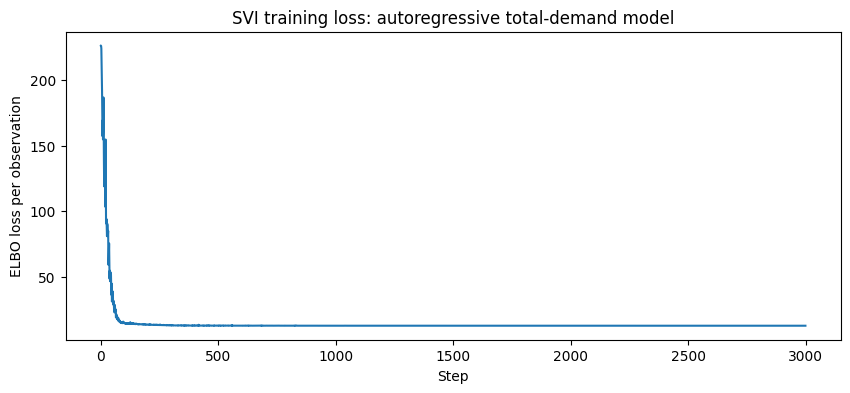

In [207]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ar)
ax.set_title("SVI training loss: autoregressive total-demand model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

In [208]:
predictive_ar = Predictive(
    airport_model_ar_total,
    guide=guide_ar,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ar = predictive_ar(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    None,
    None,
)

total_samples_ar = samples_ar["total"].detach().cpu().numpy()
outs_samples_ar = samples_ar["outs"].detach().cpu().numpy()

test_ar_df["pyro_ar_total_mean"] = total_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_outs_mean"] = outs_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_ins_mean"] = (
    test_ar_df["pyro_ar_total_mean"] - test_ar_df["pyro_ar_outs_mean"]
)
test_ar_df["pyro_ar_outs_share_mean"] = (
    test_ar_df["pyro_ar_outs_mean"] / np.maximum(test_ar_df["pyro_ar_total_mean"], 1)
)

In [209]:
test_ar_df["pyro_ar_total_q05"] = np.quantile(total_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_total_q95"] = np.quantile(total_samples_ar, 0.95, axis=0)

test_ar_df["pyro_ar_outs_q05"] = np.quantile(outs_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_outs_q95"] = np.quantile(outs_samples_ar, 0.95, axis=0)

outs_share_samples_ar = outs_samples_ar / np.maximum(total_samples_ar, 1)

test_ar_df["pyro_ar_outs_share_q05"] = np.quantile(
    outs_share_samples_ar, 0.05, axis=0
)

test_ar_df["pyro_ar_outs_share_q95"] = np.quantile(
    outs_share_samples_ar, 0.95, axis=0
)

In [210]:
pyro_ar_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ar_outs_share_mean"]
    ),
}

true_direction_ar = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ar = test_ar_df["pyro_ar_outs_mean"] > test_ar_df["pyro_ar_ins_mean"]

pyro_ar_metrics["direction_accuracy"] = np.mean(
    true_direction_ar == pred_direction_ar
)

comparison.loc["pyro_ar_total_model"] = pyro_ar_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,78.452326,100.901076,42.693398,56.969952,43.671618,58.192266,0.087816,0.808060
pyro_slot_weekday_model,69.874013,90.346756,38.779238,52.059322,39.772405,53.273531,0.087872,0.809072
pyro_ar_total_model,51.533772,67.370225,31.463029,43.490605,31.176287,42.327136,0.087866,0.808277


In [211]:
total_coverage_ar = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ar_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ar_total_q95"])
)

outs_coverage_ar = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ar_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ar_outs_q95"])
)

share_coverage_ar = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ar_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ar_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ar:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ar:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ar:.3f}")

Total 90% coverage:      0.902
Outs 90% coverage:       0.905
Out-share 90% coverage:  0.449


## Model 4: Autoregressive Total + Direction Model

This model adds short-term temporal dependence to both total demand and directional flow.

In addition to the lagged total-flow predictor from Model 3, this model also includes the previous directional share as a predictor for the current directional probability. This allows the model to learn whether departure-dominant or arrival-dominant periods tend to persist across adjacent 15-minute intervals. The likelihood is still Binomial for the directional split.

*Does previous total traffic help predict current total traffic, and does previous directionality help predict current directionality?*

In [212]:
lag_dir_train_ar = torch.tensor(
    train_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

lag_dir_test_ar = torch.tensor(
    test_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

In [ ]:
def airport_model_ar_total_direction(
    slot,
    weekday,
    lag_total,
    lag_dir,
    total_obs=None,
    outs_obs=None,
):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    # global intercepts
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # autoregressive coefficients
    alpha_lag_total = pyro.sample("alpha_lag_total", dist.Normal(0.0, 0.5))
    gamma_lag_dir = pyro.sample("gamma_lag_dir", dist.Normal(0.0, 0.5))

    # hierarchical scales
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # overdispersion for total demand
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    # weekday effects
    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # total-demand model
    log_lambda = (mu + slot_total_effect[slot] + weekday_total_effect[weekday] + alpha_lag_total * lag_total)

    lambda_ = torch.exp(log_lambda)

    # directional model
    logits_p = (eta + slot_dir_effect[slot] + weekday_dir_effect[weekday] + gamma_lag_dir * lag_dir)

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs,
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs,
        )

In [214]:
pyro.clear_param_store()

guide_ard = AutoNormal(airport_model_ar_total_direction)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ard = SVI(
    airport_model_ar_total_direction,
    guide_ard,
    optimizer,
    loss=Trace_ELBO()
)

losses_ard = []

num_steps = 3000

for step in range(num_steps):
    loss = svi_ard.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        lag_dir_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ard.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ard[-1]:.2f}")

step 0000 | loss per obs = 213.69
step 0300 | loss per obs = 12.49
step 0600 | loss per obs = 12.17
step 0900 | loss per obs = 12.16
step 1200 | loss per obs = 12.16
step 1500 | loss per obs = 12.15
step 1800 | loss per obs = 12.16
step 2100 | loss per obs = 12.15
step 2400 | loss per obs = 12.15
step 2700 | loss per obs = 12.15


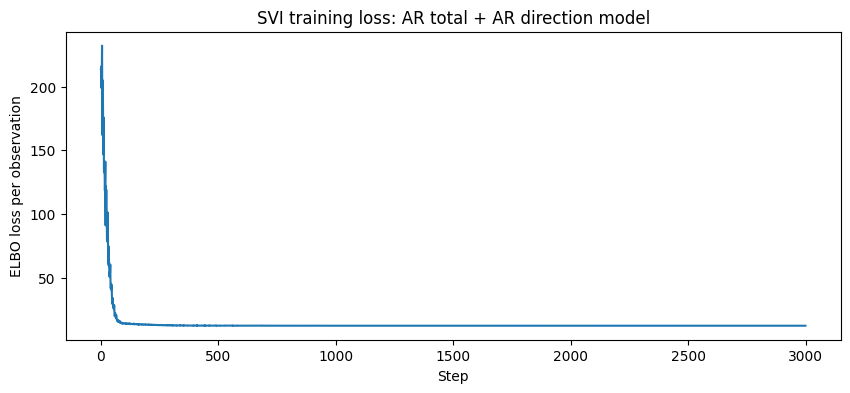

In [215]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ard)
ax.set_title("SVI training loss: AR total + AR direction model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

Posterior predictive sampling:

In [216]:
predictive_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ard = predictive_ard(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    lag_dir_test_ar,
    None,
    None,
)

total_samples_ard = samples_ard["total"].detach().cpu().numpy()
outs_samples_ard = samples_ard["outs"].detach().cpu().numpy()

In [217]:
test_ar_df["pyro_ard_total_mean"] = total_samples_ard.mean(axis=0)
test_ar_df["pyro_ard_outs_mean"] = outs_samples_ard.mean(axis=0)

test_ar_df["pyro_ard_ins_mean"] = (
    test_ar_df["pyro_ard_total_mean"] - test_ar_df["pyro_ard_outs_mean"]
)

test_ar_df["pyro_ard_outs_share_mean"] = (
    test_ar_df["pyro_ard_outs_mean"] / np.maximum(test_ar_df["pyro_ard_total_mean"], 1)
)

In [218]:
test_ar_df["pyro_ard_total_q05"] = np.quantile(total_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_total_q95"] = np.quantile(total_samples_ard, 0.95, axis=0)

test_ar_df["pyro_ard_outs_q05"] = np.quantile(outs_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_outs_q95"] = np.quantile(outs_samples_ard, 0.95, axis=0)

outs_share_samples_ard = outs_samples_ard / np.maximum(total_samples_ard, 1)

test_ar_df["pyro_ard_outs_share_q05"] = np.quantile(
    outs_share_samples_ard,
    0.05,
    axis=0
)

test_ar_df["pyro_ard_outs_share_q95"] = np.quantile(
    outs_share_samples_ard,
    0.95,
    axis=0
)

In [219]:
pyro_ard_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ard_outs_share_mean"]
    ),
}

true_direction_ard = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ard = test_ar_df["pyro_ard_outs_mean"] > test_ar_df["pyro_ard_ins_mean"]

pyro_ard_metrics["direction_accuracy"] = np.mean(
    true_direction_ard == pred_direction_ard
)

comparison.loc["pyro_ar_total_direction_model"] = pyro_ard_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,78.452326,100.901076,42.693398,56.969952,43.671618,58.192266,0.087816,0.808060
pyro_slot_weekday_model,69.874013,90.346756,38.779238,52.059322,39.772405,53.273531,0.087872,0.809072
pyro_ar_total_model,51.533772,67.370225,31.463029,43.490605,31.176287,42.327136,0.087866,0.808277
pyro_ar_total_direction_model,49.081676,64.793948,30.070638,42.062112,29.001114,39.885318,0.084726,0.808783


In [220]:
total_coverage_ard = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ard_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ard_total_q95"])
)

outs_coverage_ard = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ard_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ard_outs_q95"])
)

share_coverage_ard = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ard_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ard_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ard:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ard:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ard:.3f}")

Total 90% coverage:      0.902
Outs 90% coverage:       0.903
Out-share 90% coverage:  0.474


In [221]:
posterior_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=1000,
    return_sites=("alpha_lag_total", "gamma_lag_dir")
)

coef_samples = posterior_ard(
    slot_train_ar[:10],
    weekday_train_ar[:10],
    lag_total_train_ar[:10],
    lag_dir_train_ar[:10],
    None,
    None,
)

alpha_samples = coef_samples["alpha_lag_total"].detach().cpu().numpy()
gamma_samples = coef_samples["gamma_lag_dir"].detach().cpu().numpy()

print("alpha_lag_total:")
print("mean:", alpha_samples.mean())
print("90% CI:", np.quantile(alpha_samples, [0.05, 0.95]))

print("\ngamma_lag_dir:")
print("mean:", gamma_samples.mean())
print("90% CI:", np.quantile(gamma_samples, [0.05, 0.95]))

alpha_lag_total:
mean: 0.50906897
90% CI: [0.50613848 0.51195651]

gamma_lag_dir:
mean: 0.34552297
90% CI: [0.34398181 0.34711663]


## Model 5: Autoregressive Beta-Binomial Direction Model

This final model keeps the autoregressive structure from Model 4, but replaces the Binomial directional likelihood with a Beta-Binomial likelihood.

The motivation is that the Binomial model can be too confident about the directional split, especially when unobserved factors such as flight waves, holidays, delays, or group travel affect the airport-bound share. The Beta-Binomial likelihood introduces extra dispersion through a concentration parameter $\kappa$, allowing the model to produce wider and more realistic uncertainty intervals for $outs_t/N_t$.

In [ ]:
def airport_model_ar_betabinomial(
    slot,
    weekday,
    lag_total,
    lag_dir,
    total_obs=None,
    outs_obs=None,
):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    # global intercepts
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # autoregressive coefficients
    alpha_lag_total = pyro.sample("alpha_lag_total", dist.Normal(0.0, 0.5))
    gamma_lag_dir = pyro.sample("gamma_lag_dir", dist.Normal(0.0, 0.5))

    # hierarchical scales
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # overdispersion for total demand
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # concentration controls directional overdispersion
    # larger kappa = closer to Binomial
    # smaller kappa = more extra variability
    kappa = pyro.sample("kappa", dist.Gamma(2.0, 0.1))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # total-demand model
    log_lambda = (mu + slot_total_effect[slot] + weekday_total_effect[weekday] + alpha_lag_total * lag_total)

    lambda_ = torch.exp(log_lambda)

    # directional model
    logits_p = (eta + slot_dir_effect[slot] + weekday_dir_effect[weekday] + gamma_lag_dir * lag_dir)

    p = torch.sigmoid(logits_p)

    alpha_beta = p * kappa
    beta_beta = (1.0 - p) * kappa

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs,
        )

        betabinomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.BetaBinomial(
                concentration1=alpha_beta,
                concentration0=beta_beta,
                total_count=betabinomial_total,
            ),
            obs=outs_obs,
        )

In [223]:
pyro.clear_param_store()

guide_bb = AutoNormal(airport_model_ar_betabinomial)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})

svi_bb = SVI(
    airport_model_ar_betabinomial,
    guide_bb,
    optimizer,
    loss=Trace_ELBO()
)

losses_bb = []

num_steps = 3000

for step in range(num_steps):
    loss = svi_bb.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        lag_dir_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_bb.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_bb[-1]:.2f}")

step 0000 | loss per obs = 253.97
step 0300 | loss per obs = 10.46
step 0600 | loss per obs = 10.15
step 0900 | loss per obs = 10.11
step 1200 | loss per obs = 10.11
step 1500 | loss per obs = 10.11
step 1800 | loss per obs = 10.11
step 2100 | loss per obs = 10.11
step 2400 | loss per obs = 10.12
step 2700 | loss per obs = 10.11


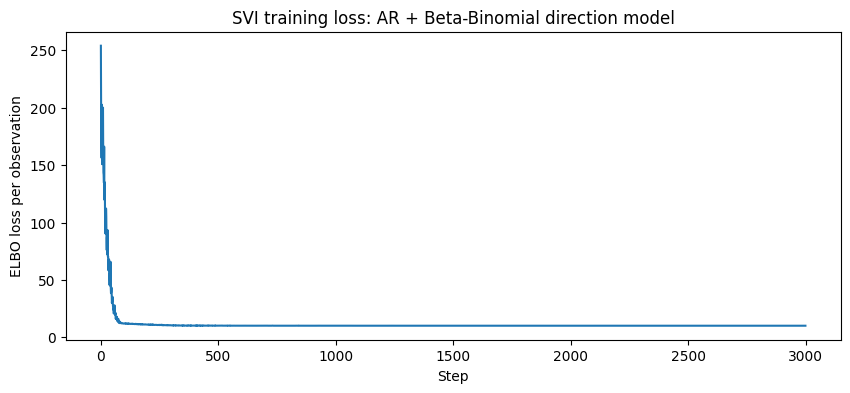

In [224]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_bb)
ax.set_title("SVI training loss: AR + Beta-Binomial direction model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

In [225]:
predictive_bb = Predictive(
    airport_model_ar_betabinomial,
    guide=guide_bb,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_bb = predictive_bb(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    lag_dir_test_ar,
    None,
    None,
)

total_samples_bb = samples_bb["total"].detach().cpu().numpy()
outs_samples_bb = samples_bb["outs"].detach().cpu().numpy()

In [226]:
test_ar_df["pyro_bb_total_mean"] = total_samples_bb.mean(axis=0)
test_ar_df["pyro_bb_outs_mean"] = outs_samples_bb.mean(axis=0)

test_ar_df["pyro_bb_ins_mean"] = (
    test_ar_df["pyro_bb_total_mean"] - test_ar_df["pyro_bb_outs_mean"]
)

test_ar_df["pyro_bb_outs_share_mean"] = (
    test_ar_df["pyro_bb_outs_mean"] / np.maximum(test_ar_df["pyro_bb_total_mean"], 1)
)

In [227]:
test_ar_df["pyro_bb_total_q05"] = np.quantile(total_samples_bb, 0.05, axis=0)
test_ar_df["pyro_bb_total_q95"] = np.quantile(total_samples_bb, 0.95, axis=0)

test_ar_df["pyro_bb_outs_q05"] = np.quantile(outs_samples_bb, 0.05, axis=0)
test_ar_df["pyro_bb_outs_q95"] = np.quantile(outs_samples_bb, 0.95, axis=0)

outs_share_samples_bb = outs_samples_bb / np.maximum(total_samples_bb, 1)

test_ar_df["pyro_bb_outs_share_q05"] = np.quantile(
    outs_share_samples_bb,
    0.05,
    axis=0
)

test_ar_df["pyro_bb_outs_share_q95"] = np.quantile(
    outs_share_samples_bb,
    0.95,
    axis=0
)

In [228]:
pyro_bb_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_bb_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_bb_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_bb_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_bb_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_bb_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_bb_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_bb_outs_share_mean"]
    ),
}

true_direction_bb = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_bb = test_ar_df["pyro_bb_outs_mean"] > test_ar_df["pyro_bb_ins_mean"]

pyro_bb_metrics["direction_accuracy"] = np.mean(
    true_direction_bb == pred_direction_bb
)

comparison.loc["pyro_ar_betabinomial_model"] = pyro_bb_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,78.452326,100.901076,42.693398,56.969952,43.671618,58.192266,0.087816,0.808060
pyro_slot_weekday_model,69.874013,90.346756,38.779238,52.059322,39.772405,53.273531,0.087872,0.809072
pyro_ar_total_model,51.533772,67.370225,31.463029,43.490605,31.176287,42.327136,0.087866,0.808277
pyro_ar_total_direction_model,49.081676,64.793948,30.070638,42.062112,29.001114,39.885318,0.084726,0.808783
pyro_ar_betabinomial_model,50.225574,65.993686,30.937791,42.740834,29.681361,40.691247,0.084120,0.807987


In [230]:
total_coverage_bb = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_bb_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_bb_total_q95"])
)

outs_coverage_bb = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_bb_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_bb_outs_q95"])
)

share_coverage_bb = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_bb_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_bb_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_bb:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_bb:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_bb:.3f}")

Total 90% coverage:      0.902
Outs 90% coverage:       0.919
Out-share 90% coverage:  0.855


In [231]:
posterior_bb = Predictive(
    airport_model_ar_betabinomial,
    guide=guide_bb,
    num_samples=1000,
    return_sites=("alpha_lag_total", "gamma_lag_dir", "kappa")
)

coef_samples_bb = posterior_bb(
    slot_train_ar[:10],
    weekday_train_ar[:10],
    lag_total_train_ar[:10],
    lag_dir_train_ar[:10],
    None,
    None,
)

alpha_samples_bb = coef_samples_bb["alpha_lag_total"].detach().cpu().numpy()
gamma_samples_bb = coef_samples_bb["gamma_lag_dir"].detach().cpu().numpy()
kappa_samples_bb = coef_samples_bb["kappa"].detach().cpu().numpy()

print("alpha_lag_total:")
print("mean:", alpha_samples_bb.mean())
print("90% CI:", np.quantile(alpha_samples_bb, [0.05, 0.95]))

print("\ngamma_lag_dir:")
print("mean:", gamma_samples_bb.mean())
print("90% CI:", np.quantile(gamma_samples_bb, [0.05, 0.95]))

print("\nkappa:")
print("mean:", kappa_samples_bb.mean())
print("90% CI:", np.quantile(kappa_samples_bb, [0.05, 0.95]))

alpha_lag_total:
mean: 0.5154566
90% CI: [0.51289422 0.51798976]

gamma_lag_dir:
mean: 0.18972231
90% CI: [0.18596772 0.19373046]

kappa:
mean: 41.063618
90% CI: [40.55901413 41.5973259 ]


# Plots

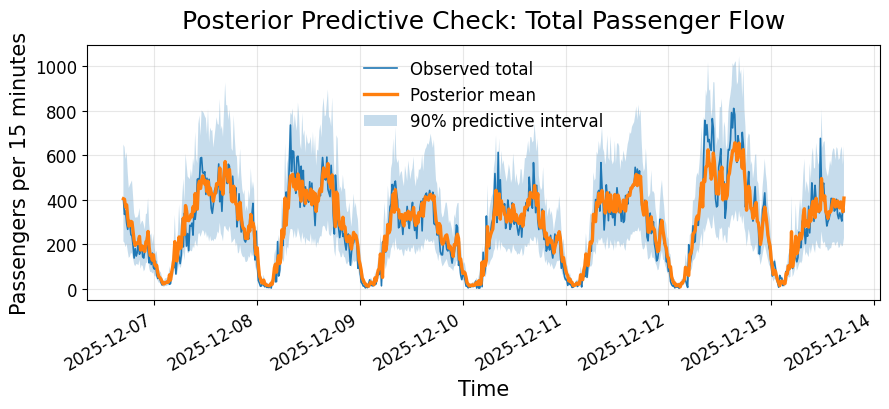

Saved figure to: figures/posterior_predictive_total_flow.pdf


In [ ]:
from pathlib import Path

FIG_DIR = Path("figures")

FIG_PATH = FIG_DIR / "posterior_predictive_total_flow.pdf"

WEEK = 5

week_left = (WEEK - 1) * 96 * 7 + 2*96
week_right = WEEK * 96 * 7 + 2*96


plot_df = test_ar_df.iloc[week_left : week_right].copy()
plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"], utc=True)

fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(
    plot_df["timestamp"],
    plot_df["total"],
    label="Observed total",
    linewidth=1.2,
)

ax.plot(
    plot_df["timestamp"],
    plot_df["pyro_ard_total_mean"],
    label="Posterior mean",
    linewidth=2.4,
)

ax.fill_between(
    plot_df["timestamp"],
    plot_df["pyro_ard_total_q05"],
    plot_df["pyro_ard_total_q95"],
    alpha=0.25,
    label="90% predictive interval",
)

ax.set_title(
    "Posterior Predictive Check: Total Passenger Flow",
    fontsize=18,
    pad=12,
)
ax.set_xlabel("Time", fontsize=15)
ax.set_ylabel("Passengers per 15 minutes", fontsize=15)

ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=12, loc="best")

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_PATH, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {FIG_PATH}")

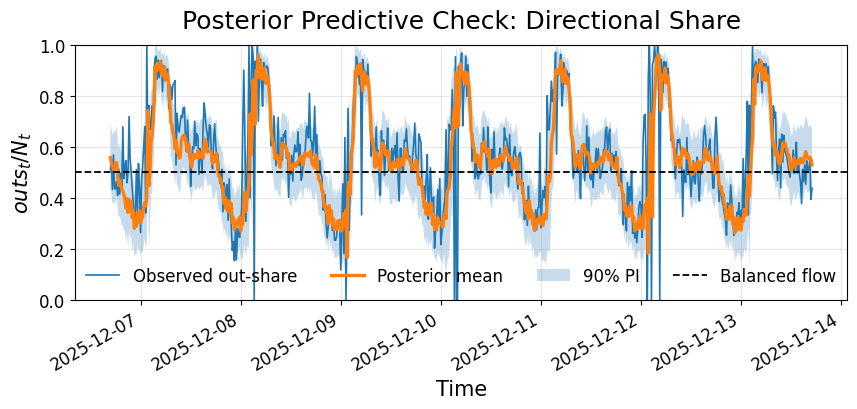

Saved figure to: figures/posterior_predictive_direction_share.pdf


In [ ]:
from pathlib import Path

FIG_PATH = FIG_DIR / "posterior_predictive_direction_share.pdf"


WEEK = 5
week_left = (WEEK - 1) * 96 * 7 + 2*96
week_right = WEEK * 96 * 7 + 2*96


plot_df = test_ar_df.iloc[week_left : week_right].copy()
plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"], utc=True)


fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(
    plot_df["timestamp"],
    plot_df["outs_share"],
    label="Observed out-share",
    linewidth=1.2,
    # label="_nolegend_",
)

ax.plot(
    plot_df["timestamp"],
    plot_df["pyro_bb_outs_share_mean"],
    linewidth=2.4,
    label="Posterior mean",
    # label="_nolegend_",
)

ax.fill_between(
    plot_df["timestamp"],
    plot_df["pyro_bb_outs_share_q05"],
    plot_df["pyro_bb_outs_share_q95"],
    alpha=0.25,
    label="90% PI",
    # label="_nolegend_",
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.3,
    color="black",
    label="Balanced flow",
)

ax.set_title(
    "Posterior Predictive Check: Directional Share",
    fontsize=18,
    pad=12,
)

ax.set_xlabel("Time", fontsize=15)
ax.set_ylabel(r"$outs_t / N_t$", fontsize=15)

ax.set_ylim(0, 1)
ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)

ax.legend(
    frameon=False,
    fontsize=12,
    loc="lower center",
    ncol=4,
)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_PATH, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {FIG_PATH}")